# Model Implementation 
### SALSABILA AURELIA OKTANIOPUTRI TP078641

In [ ]:
!pip install prophet

In [ ]:
!pip install plotly

##### 1. IMPORT LIBRARIES & RELOAD DATA FRAME
- train: 146 rows; val: 21 rows; test: 42 rows
- check the data types are ds: datetime ; y: float

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

plt.rcParams['figure.figsize'] = (14, 5)

# Reload cleaned data, fixing datetime dtype lost in CSV
df_weekly_clean = pd.read_csv('data/df_weekly_clean.csv', parse_dates=['ds'])
train = pd.read_csv('data/train.csv', parse_dates=['ds'])
val   = pd.read_csv('data/val.csv', parse_dates=['ds'])
test  = pd.read_csv('data/test.csv', parse_dates=['ds'])

print(f"Full series : {df_weekly_clean.shape}")
print(f"Train       : {train.shape}, {train['ds'].min().date()} to {train['ds'].max().date()}")
print(f"Validation  : {val.shape}, {val['ds'].min().date()} to {val['ds'].max().date()}")
print(f"Test        : {test.shape}, {test['ds'].min().date()} to {test['ds'].max().date()}")

Full series : (209, 2)
Train       : (146, 2), 2020-01-05 to 2022-10-16
Validation  : (21, 2), 2022-10-23 to 2023-03-12
Test        : (42, 2), 2023-03-19 to 2023-12-31


In [4]:
print("-- weekly aggregated cleaned df data types")
print(df_weekly_clean.dtypes)
print("-- train data types")
print(train.dtypes)
print("-- validation data types")
print(val.dtypes)
print("-- test data types")
print(test.dtypes)

-- weekly aggregated cleaned df data types
ds    datetime64[us]
y            float64
dtype: object
-- train data types
ds    datetime64[us]
y            float64
dtype: object
-- validation data types
ds    datetime64[us]
y            float64
dtype: object
-- test data types
ds    datetime64[us]
y            float64
dtype: object


##### 2) SARIMA PRE-CHECKING / CONFIG
- ADF TEST: to check for stationarity. SARIMA mathematically needs stationarity. If pval > 0.05 non stationary (means balance between mean&variance). Allows us to test how much differencing (d) we need to apply. After differncing pval should be <0.05
- ACF/PACF TEST: we plot correlation & autocoralation functions. We can get starting value for p (how many past values to use) & q (how many past values to use)

In [5]:
# 2.1) SARIMA CHECK 1:

def adf_test(series, label=''):
    result = adfuller(series.dropna())
    print(f"--- ADF Test: {label} ---")
    print(f"ADF Statistic : {result[0]:.4f}")
    print(f"p-value       : {result[1]:.4f}")
    if result[1] <= 0.05:
        print("=> Stationary (reject H0)")
    else:
        print("=> Non-stationary (fail to reject H0)")
    print()

# Test on raw training series
adf_test(train['y'], 'Original training series')

# Apply first-order differencing
train_diff1 = train['y'].diff().dropna()
adf_test(train_diff1, 'After 1st-order differencing (d=1)')

# Apply seasonal differencing (lag 52) on top, if still non-stationary
train_diff_seasonal = train['y'].diff().diff(52).dropna()
adf_test(train_diff_seasonal, 'After d=1 + seasonal D=1 (lag 52)')

--- ADF Test: Original training series ---
ADF Statistic : -3.2242
p-value       : 0.0186
=> Stationary (reject H0)

--- ADF Test: After 1st-order differencing (d=1) ---
ADF Statistic : -16.9415
p-value       : 0.0000
=> Stationary (reject H0)

--- ADF Test: After d=1 + seasonal D=1 (lag 52) ---
ADF Statistic : -5.0833
p-value       : 0.0000
=> Stationary (reject H0)



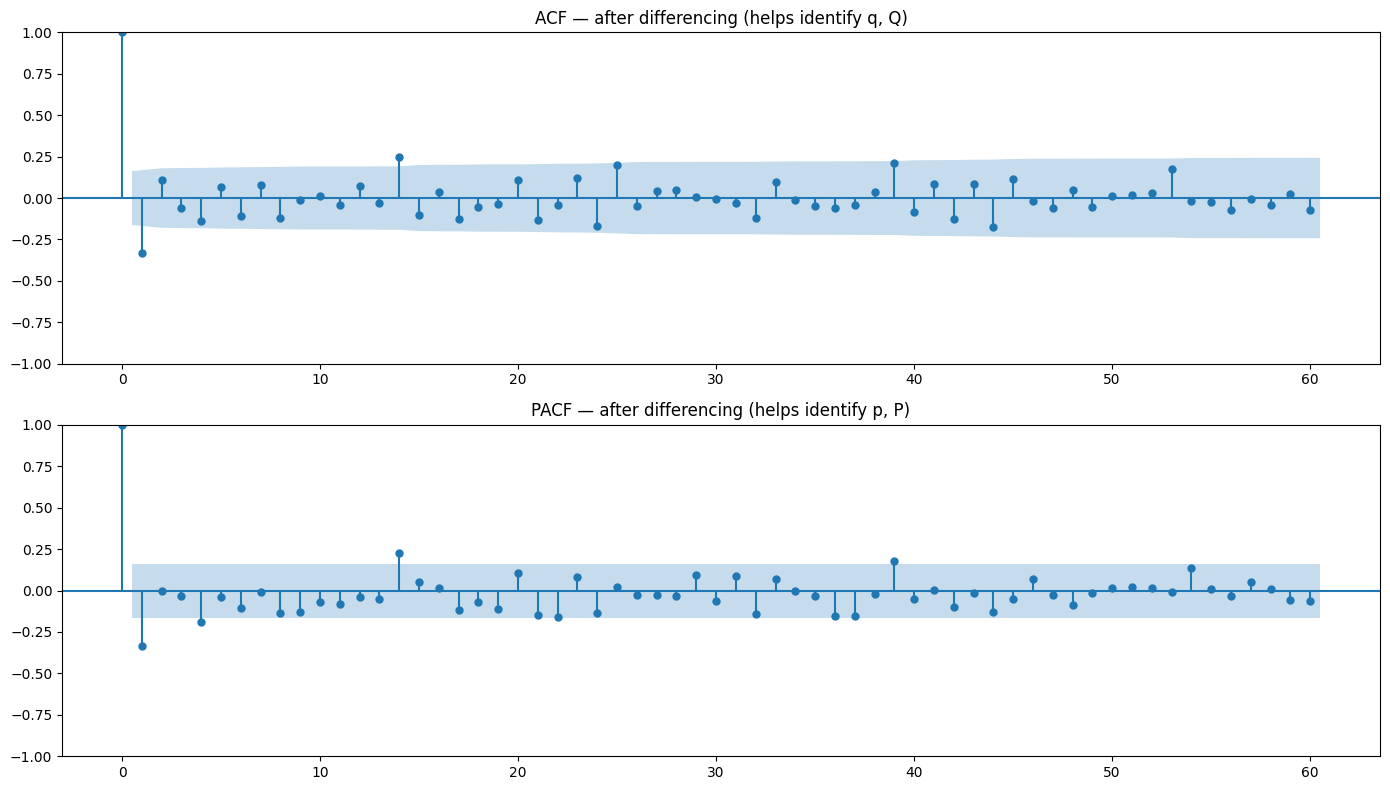

In [6]:
# 2.2) SARIMA CHECK 2: ACF/PACF Analysis
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
plot_acf(train_diff1, lags=60, ax=axes[0])
axes[0].set_title('ACF — after differencing (helps identify q, Q)')
plot_pacf(train_diff1, lags=60, ax=axes[1])
axes[1].set_title('PACF — after differencing (helps identify p, P)')
plt.tight_layout()
plt.show()

##### 3) PROPHET CONFIG
- choose seasonality mode = multiplactive, because EDA shows that as demand grows - seasonal swings also grow. (additive used if seasonal swings stay the same regardless of demand growth)
- weekly seasonality = false: because my data is already aggregated to weekly totals so there is no day of the week pattern to detect
- interval_width=0.95

In [7]:
# 3) PROPHET Configuration
model_prophet = Prophet(
    seasonality_mode='multiplicative',   # because seasonal amplitude grows with the trend (seen in EDA3/EDA6)
    yearly_seasonality=True,
    weekly_seasonality=False,            # not meaningful at weekly aggregation level
    daily_seasonality=False,
    interval_width=0.95                  # MATCH SARIMA's 95% confidence interval — critical for fair comparison later
)

##### 4) DEFINE FORECAST HORIZON

In [ ]:
# 4) Define Forecast Horizon
FORECAST_HORIZON = len(test)
print(f"Forecast horizon: {FORECAST_HORIZON} weeks (single multi-step forecast)")

Forecast horizon: 42 weeks (single multi-step forecast)


#### 5) MODEL FITTING

In [9]:
# 5.1) Model Fitting SARIMA 
# SARIMA — use ADF/ACF/PACF findings as STARTING values; final values chosen in Step 6
sarima_order = (1, 1, 1)              
sarima_seasonal_order = (1, 1, 1, 52) 

model_sarima = SARIMAX(
    train['y'],
    order=sarima_order,
    seasonal_order=sarima_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)
sarima_fit = model_sarima.fit(disp=False)
print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                  146
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 52)   Log Likelihood                -267.321
Date:                            Tue, 07 Jul 2026   AIC                            544.642
Time:                                    21:10:08   BIC                            552.960
Sample:                                         0   HQIC                           547.627
                                            - 146                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1891      0.320      0.591      0.554      -0.438       0.816
ma.L1         -0.8603      0.112   

In [ ]:
# 5.2) Prophet requires columns named exactly 'ds' and 'y' — already matches your naming
model_prophet.fit(train[['ds', 'y']])
print("Prophet fitted on training data.")

21:20:53 - cmdstanpy - INFO - Chain [1] start processing
21:20:55 - cmdstanpy - INFO - Chain [1] done processing


Prophet fitted on training data.


#### 6) HYPERPARAMETER TUNING

In [ ]:
# 7) Hyperparameter Tuning 1: SARIMA
from sklearn.metrics import mean_squared_error
from itertools import product

# ── SARIMA grid search ─────────────────────────────────────────────
p_vals = [0, 1, 2]
d_vals = [1]              # locked in from ADF test result
q_vals = [0, 1, 2]
P_vals = [0, 1]
D_vals = [1]              # locked in from seasonal differencing result
Q_vals = [0, 1]
S = 52

best_rmse = np.inf
best_params = None
results_log = []

for p, d, q, P, D, Q in product(p_vals, d_vals, q_vals, P_vals, D_vals, Q_vals):
    try:
        m = SARIMAX(train['y'], order=(p,d,q), seasonal_order=(P,D,Q,S),
                    enforce_stationarity=False, enforce_invertibility=False)
        fit = m.fit(disp=False)
        forecast = fit.get_forecast(steps=len(val))
        pred = forecast.predicted_mean
        rmse = np.sqrt(mean_squared_error(val['y'], pred))
        results_log.append((p,d,q,P,D,Q, fit.aic, rmse))
        if rmse < best_rmse:
            best_rmse = rmse
            best_params = (p,d,q,P,D,Q)
    except Exception as e:
        continue

print(f"Best SARIMA params (p,d,q,P,D,Q): {best_params}")
print(f"Best validation RMSE: {best_rmse:.2f}")

results_df = pd.DataFrame(results_log, columns=['p','d','q','P','D','Q','AIC','val_RMSE'])
results_df.sort_values('val_RMSE').head(10)

In [ ]:
# 8) Hyperparameter Tuning 3: Prophet 
# ── Prophet tuning ──────────────────────────────────────────────────
changepoint_scales = [0.001, 0.01, 0.05, 0.1, 0.5]
seasonality_scales = [0.01, 1.0, 10.0]

best_prophet_rmse = np.inf
best_prophet_params = None
prophet_results_log = []

for cps, sps in product(changepoint_scales, seasonality_scales):
    m = Prophet(
        seasonality_mode='multiplicative',
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        interval_width=0.95,
        changepoint_prior_scale=cps,
        seasonality_prior_scale=sps
    )
    m.fit(train[['ds', 'y']])
    future_val = val[['ds']]
    fcst = m.predict(future_val)
    rmse = np.sqrt(mean_squared_error(val['y'], fcst['yhat']))
    prophet_results_log.append((cps, sps, rmse))
    if rmse < best_prophet_rmse:
        best_prophet_rmse = rmse
        best_prophet_params = (cps, sps)

print(f"Best Prophet params (changepoint, seasonality): {best_prophet_params}")
print(f"Best validation RMSE: {best_prophet_rmse:.2f}")

In [ ]:
# 9) Refit Model on Training Data with Best Hyperparameters
p,d,q,P,D,Q = best_params
final_sarima = SARIMAX(train['y'], order=(p,d,q), seasonal_order=(P,D,Q,52),
                        enforce_stationarity=False, enforce_invertibility=False)
final_sarima_fit = final_sarima.fit(disp=False)

cps, sps = best_prophet_params
final_prophet = Prophet(
    seasonality_mode='multiplicative',
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95,
    changepoint_prior_scale=cps,
    seasonality_prior_scale=sps
)
final_prophet.fit(train[['ds', 'y']])

print(f"Final SARIMA order: ({p},{d},{q})({P},{D},{Q},52)")
print(f"Final Prophet params: changepoint_prior_scale={cps}, seasonality_prior_scale={sps}")

In [ ]:
# 10) Forecast Generation
# SARIMA forecast
sarima_forecast_obj = final_sarima_fit.get_forecast(steps=FORECAST_HORIZON)
sarima_pred = sarima_forecast_obj.predicted_mean
sarima_ci = sarima_forecast_obj.conf_int(alpha=0.05)  # 95% CI, matches Prophet's interval_width=0.95

sarima_results = pd.DataFrame({
    'ds': test['ds'].values,
    'actual': test['y'].values,
    'predicted': sarima_pred.values,
    'lower_ci': sarima_ci.iloc[:, 0].values,
    'upper_ci': sarima_ci.iloc[:, 1].values
})

# Prophet forecast
future_test = test[['ds']]
prophet_fcst = final_prophet.predict(future_test)

prophet_results = pd.DataFrame({
    'ds': test['ds'].values,
    'actual': test['y'].values,
    'yhat': prophet_fcst['yhat'].values,
    'yhat_lower': prophet_fcst['yhat_lower'].values,
    'yhat_upper': prophet_fcst['yhat_upper'].values,
    'trend': prophet_fcst['trend'].values,
    'seasonal': prophet_fcst['multiplicative_terms'].values
})

print("SARIMA results:")
print(sarima_results.head())
print("\nProphet results:")
print(prophet_results.head())

In [ ]:
# 11) Check Alignment
assert (sarima_results['ds'].values == prophet_results['ds'].values).all(), "Date mismatch between models!"
print("Date alignment confirmed — both models forecast the exact same weeks.")

In [ ]:
# 12) Export Results to Dashboard
sarima_results.to_csv('model_sarima_results.csv', index=False)
prophet_results.to_csv('model_prophet_results.csv', index=False)

print("Saved: model_sarima_results.csv")
print("Saved: model_prophet_results.csv")
print(f"\nForecast type used: SINGLE multi-step forecast, {FORECAST_HORIZON} weeks, no rolling/intermediate actuals used.")